# W11. Neuroinformatyka i biosygnały

**Wersja źródła:** 1.1.6 · **Data:** 2026-11-04

In [1]:
import numpy as np
rng = np.random.default_rng(11)
fs = 250
czas = np.arange(0, 300, 1/fs)
rr0 = .8 + .05*np.sin(np.linspace(0, 12, 480)) + rng.normal(0, .012, 480)
r_czasy = np.cumsum(rr0)
r_czasy = r_czasy[(r_czasy > .5) & (r_czasy < 299)]
ecg = .015*rng.normal(size=czas.size)
for r in r_czasy:
    k = round(r*fs)
    for przes, amp, sig in [(-50, .10, 9), (0, 1., 2), (75, .28, 16)]:
        lo, hi = max(0, k+przes-3*sig), min(ecg.size, k+przes+3*sig)
        j = np.arange(lo, hi)
        ecg[j] += amp*np.exp(-.5*((j-(k+przes))/sig)**2)
print("Syntetyczne próbki:", ecg.size)


Syntetyczne próbki: 75000


In [2]:
from scipy.signal import find_peaks
szczyty, _ = find_peaks(ecg, height=.65, distance=int(.45*fs))
print("Wykryte piki R:", len(szczyty))
r_ref = np.rint(r_czasy * fs).astype(int)
trafione = np.array([np.min(np.abs(szczyty - k)) <= 5 for k in r_ref])
falszywe = sum(np.min(np.abs(r_ref - k)) > 5 for k in szczyty)
print("Referencyjne R:", len(r_ref), "czułość:", round(trafione.mean(), 3),
      "fałszywe detekcje:", falszywe)


Wykryte piki R: 368
Referencyjne R: 368 czułość: 1.0 fałszywe detekcje: 0


In [3]:
nn_ms = np.diff(szczyty)/fs*1000
sdnn = np.std(nn_ms, ddof=1)
rmssd = np.sqrt(np.mean(np.diff(nn_ms)**2))
print(f"Średnie tętno: {60000/np.mean(nn_ms):.1f} /min")
print(f"SDNN: {sdnn:.1f} ms, RMSSD: {rmssd:.1f} ms")

# Celowa symulacja pominięcia jednego R (RR nie jest wtedy prawidłowym NN)
rr_blad = np.diff(np.delete(szczyty, len(szczyty)//2)) / fs * 1000
rmssd_blad = np.sqrt(np.mean(np.diff(rr_blad)**2))
print(f"RMSSD po pominięciu R: {rmssd_blad:.1f} ms")


Średnie tętno: 74.0 /min
SDNN: 36.5 ms, RMSSD: 16.8 ms
RMSSD po pominięciu R: 56.6 ms


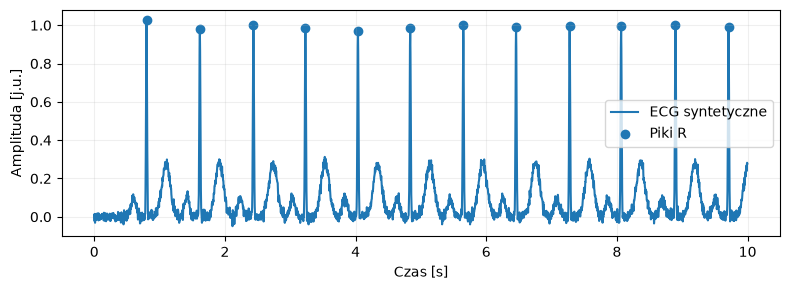

In [4]:
import matplotlib.pyplot as plt
m = czas < 10
r = szczyty[czas[szczyty] < 10]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(czas[m], ecg[m], label="ECG syntetyczne")
ax.scatter(czas[r], ecg[r], label="Piki R")
ax.set(xlabel="Czas [s]", ylabel="Amplituda [j.u.]")
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
